# LungCT pTVReg vs MR-D-BSCP P2e landmark residual atlas

This executed review notebook renders the ten 4DCT and ten COPD cases using the fixed best-aggregate P2e variants. It performs posthoc loading and validation only; no registration is run.

In [1]:
from pathlib import Path
import sys
import pandas as pd

candidates = [Path.cwd(), Path.cwd() / 'experiments/2026-09-02_lungct_ptvreg_vs_mrdbscp_p2e_landmark_atlas']
EXPERIMENT_DIR = next((candidate for candidate in candidates if (candidate / 'landmark_residual_atlas.py').is_file()), None)
if EXPERIMENT_DIR is None:
    raise RuntimeError('Could not locate landmark_residual_atlas.py; run from the repository root or this experiment directory')
sys.path.insert(0, str(EXPERIMENT_DIR))
from landmark_residual_atlas import render_all

REPORT_DIR = EXPERIMENT_DIR / 'reports'
print('Experiment directory:', EXPERIMENT_DIR.name)
print('Report directory:', REPORT_DIR.name)

Experiment directory: 2026-09-02_lungct_ptvreg_vs_mrdbscp_p2e_landmark_atlas
Report directory: reports


In [2]:
artifacts = render_all(REPORT_DIR)
summary = pd.DataFrame(artifacts['summary_rows'])
assert summary.shape[0] == 20
assert summary['landmarks'].eq(300).all()
summary[['dataset', 'case_id', 'initial_tre_mean_mm', 'ptvreg_tre_mean_mm', 'p2e_tre_mean_mm', 'ptvreg_applied_motion_p95_mm', 'p2e_applied_motion_p95_mm']]

loaded 4dct case01


loaded 4dct case02


loaded 4dct case03


loaded 4dct case04


loaded 4dct case05


loaded 4dct case06


... (13 outputs left out)

loaded copd case10


rendered 4dct atlas


rendered copd atlas


,dataset,case_id,initial_tre_mean_mm,ptvreg_tre_mean_mm,p2e_tre_mean_mm,ptvreg_applied_motion_p95_mm,p2e_applied_motion_p95_mm
0,4dct,1,3.892406,0.767141,0.792579,9.411262,9.620997
1,4dct,2,4.337842,0.750864,0.771028,14.606047,14.595070
2,4dct,3,6.942993,0.927378,0.936218,14.495268,14.642716
3,4dct,4,9.830147,1.265704,1.253899,17.273466,17.339015
4,4dct,5,7.476853,1.077725,1.093369,17.748889,17.819367
5,4dct,6,10.891024,0.831637,0.828364,23.810090,23.887697
6,4dct,7,11.026220,0.806061,0.796233,25.974316,26.041016
7,4dct,8,14.994681,1.014220,1.007241,28.102296,28.143802
8,4dct,9,7.918264,0.909508,0.886601,13.064352,13.095107
9,4dct,10,7.301382,0.840979,0.808533,22.301638,22.395541


4dct 4dct_ptvreg_vs_mrdbscp_p2e_landmark_atlas.png


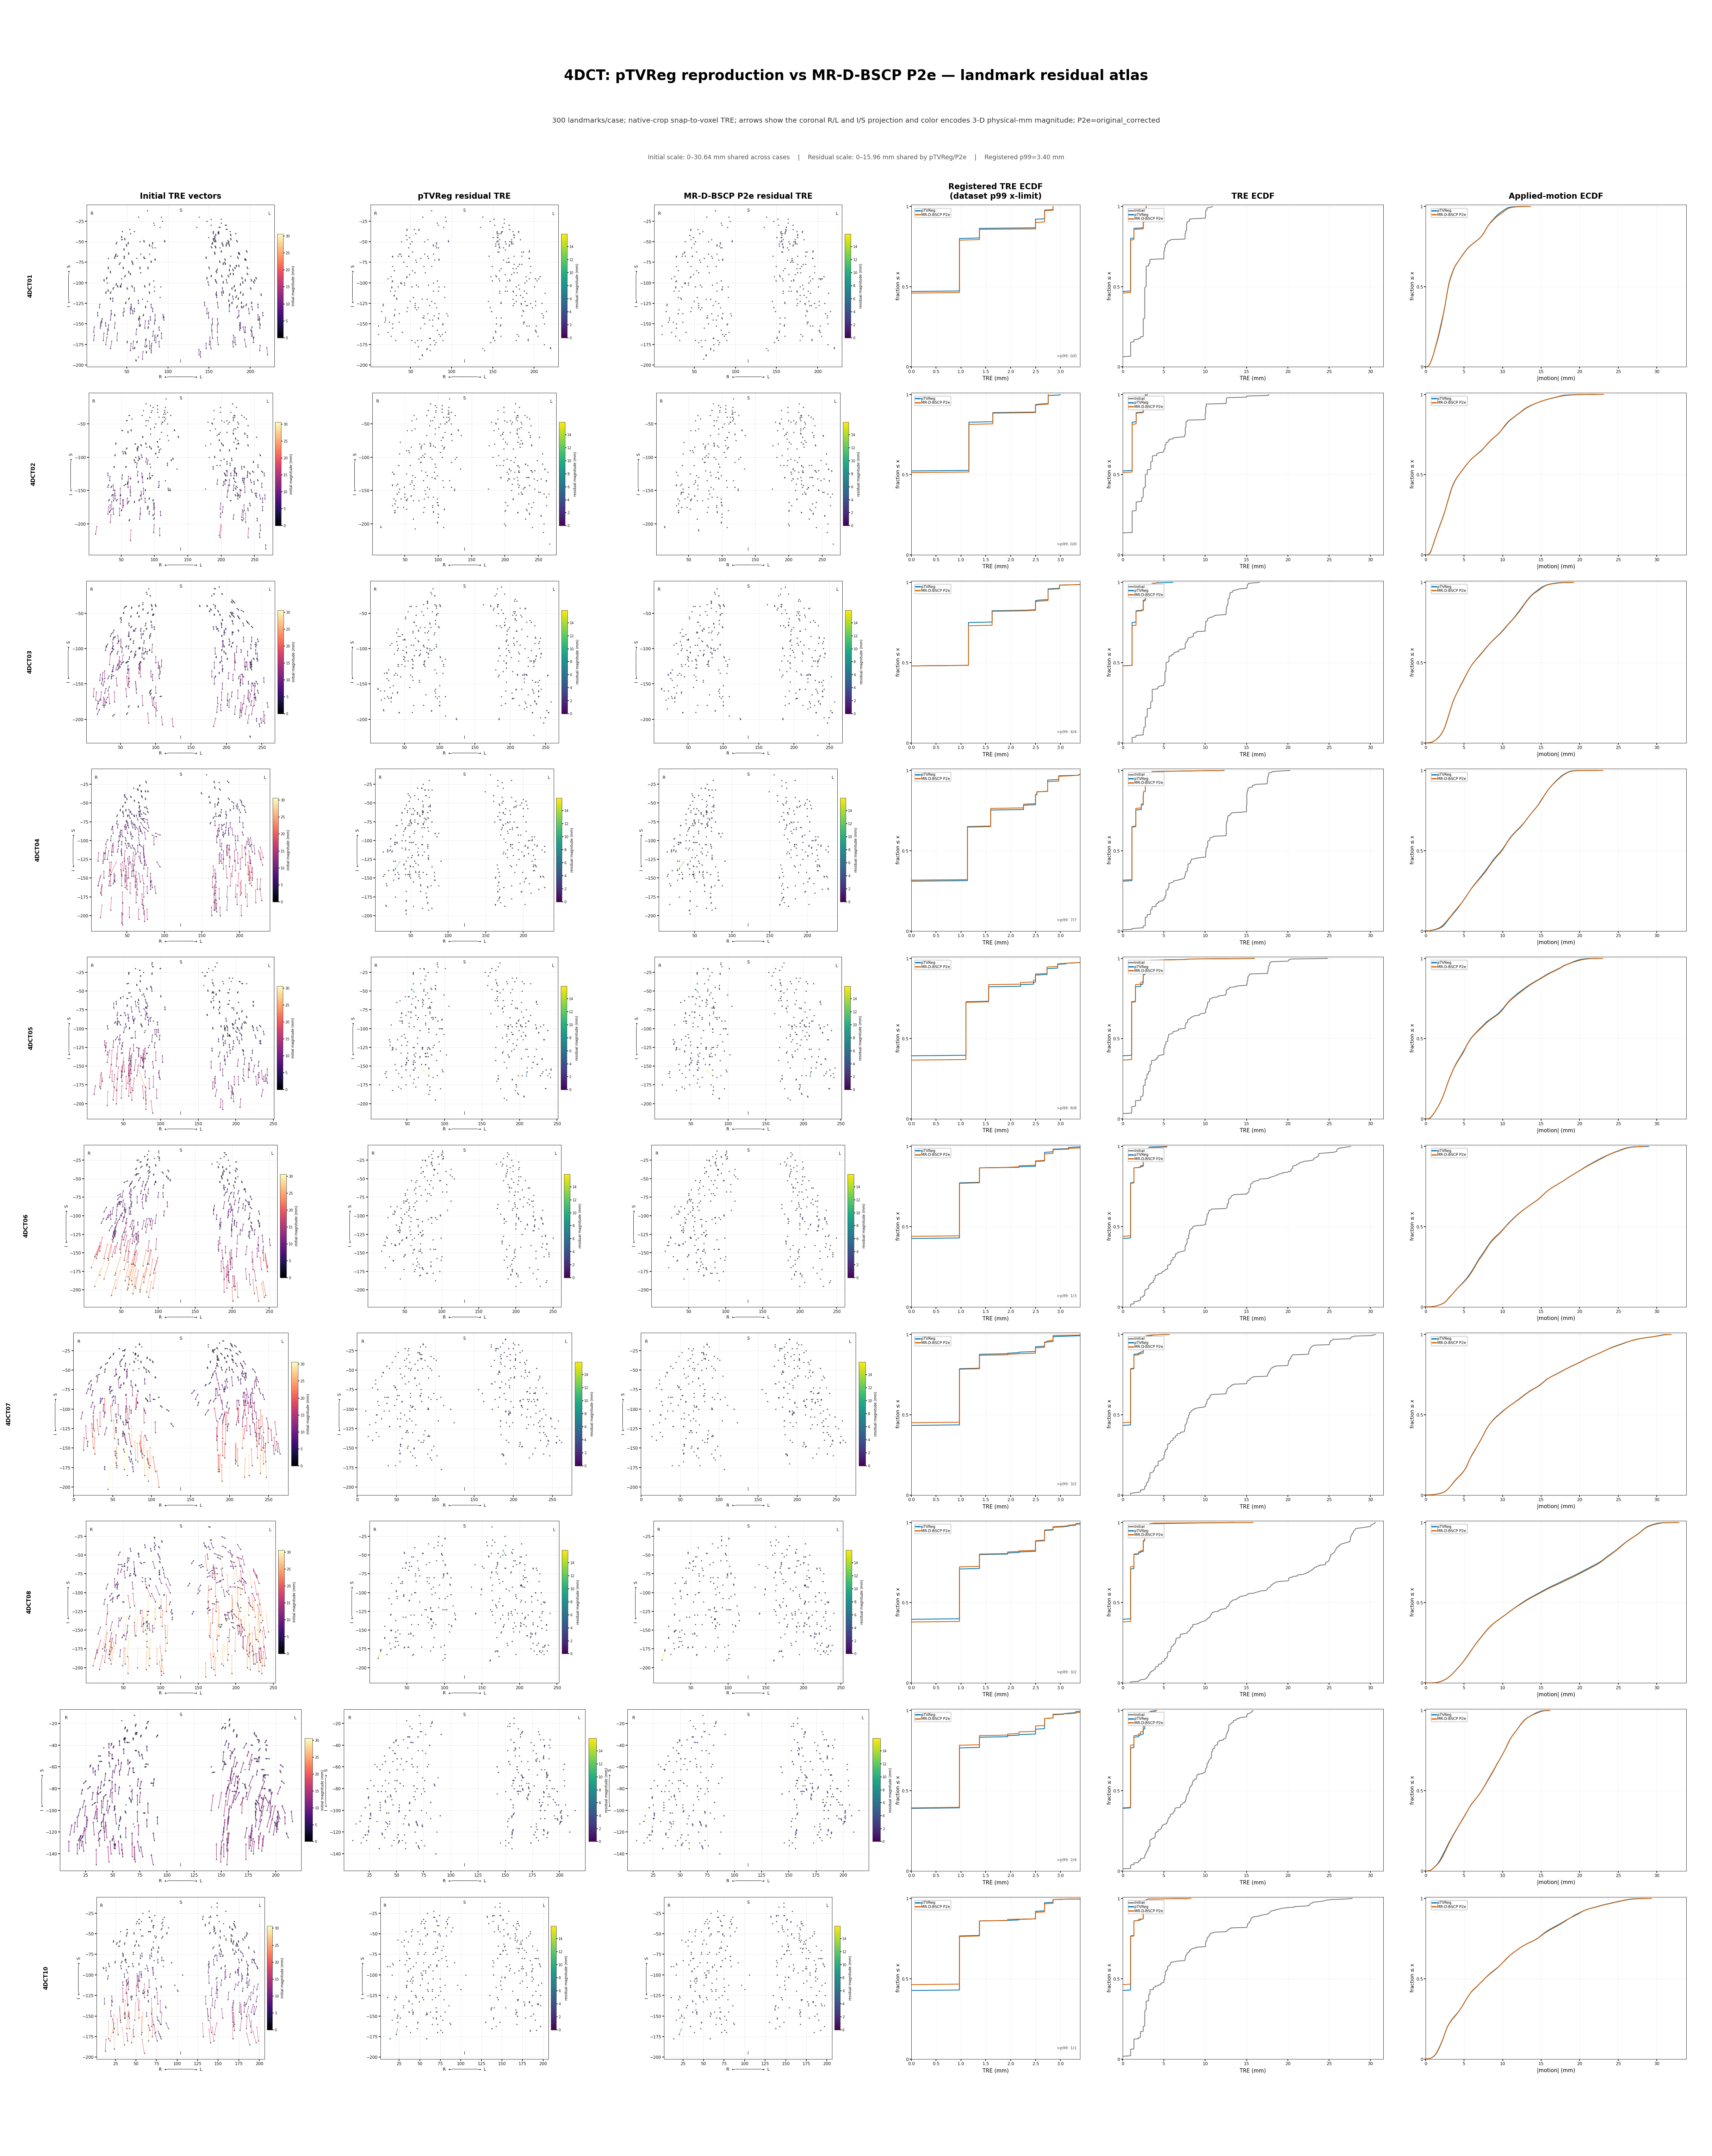

copd copd_ptvreg_vs_mrdbscp_p2e_landmark_atlas.png


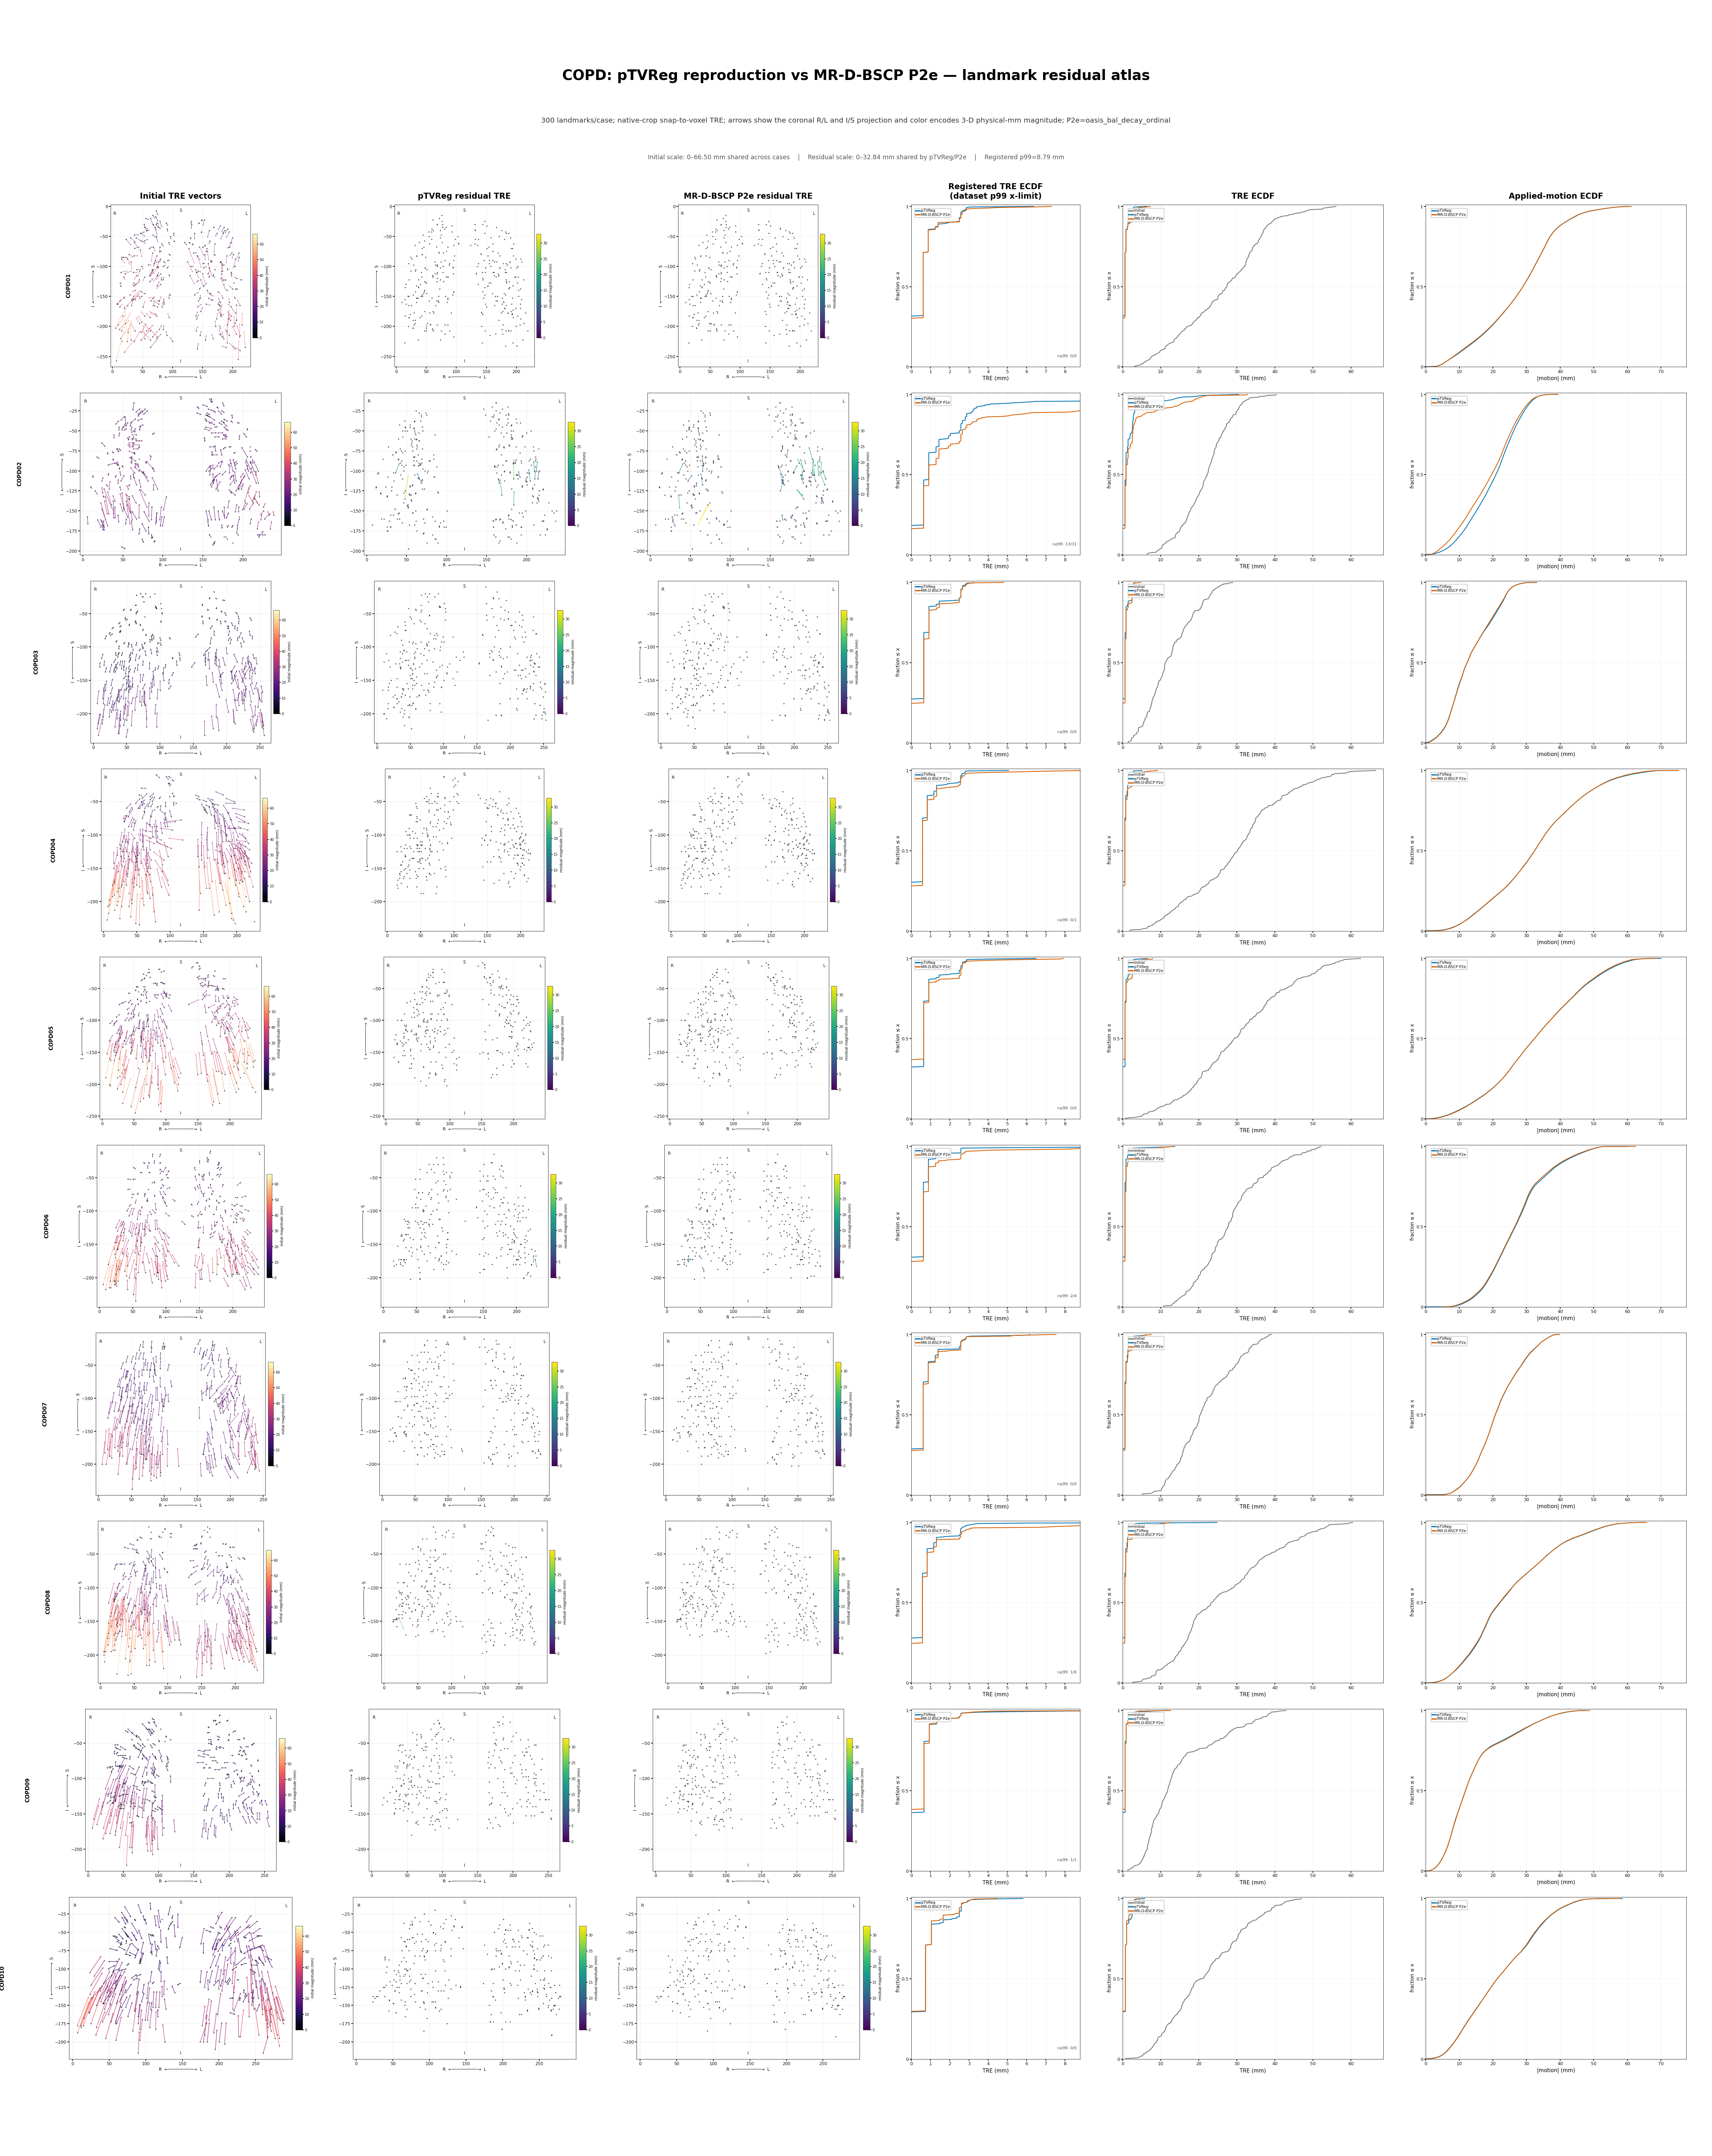

Summary: casewise_landmark_atlas_summary.csv
Provenance: provenance.json


In [3]:
from IPython.display import Image, display

for atlas in artifacts['atlas_info']:
    atlas_path = REPORT_DIR / atlas['output_path']
    print(atlas['dataset'], atlas_path.name)
    display(Image(filename=str(atlas_path), width=1500))

print('Summary:', artifacts['summary_path'].name)
print('Provenance:', artifacts['provenance_path'].name)